In [1]:
import regex as re
import pathlib
from IPython.display import Markdown as md

import keras
from keras import ops
from keras import layers
from keras.utils import to_categorical
from keras.utils import text_dataset_from_directory

import tensorflow as tf
import pickle
import matplotlib.pyplot as plt
import numpy as np

import os

### Methoden en Technieken (M&T), blok 2 - Les 2

In de vorige les hebben we een korte introductie gegeven op NLP en hebben we een voorbeeld gegeven van een tekst-classificatie-opdracht.

<br>

Deze opdracht hebben we uitgevoerd met een bag-of-words-model (en variant).

<br>

In deze les hervatten we de opdracht en introduceren we sequence-models.

### Verantwoording code

De inhoud is grotendeels gebaseerd op H14 en H15 uit [*Deep Learning with Python*](https://deeplearningwithpython.io/).<br>
De code komt grotendeels van<br>
[https://github.com/fchollet/deep-learning-with-python-notebooks](https://github.com/fchollet/deep-learning-with-python-notebooks)

In [2]:
train_dir = pathlib.Path("C:/Users/Ik/.keras/datasets/imdb/imdb_train")
test_dir = pathlib.Path("C:/Users/Ik/.keras/datasets/imdb/imdb_test")
val_dir = pathlib.Path("C:/Users/Ik/.keras/datasets/imdb/imdb_val")

In [3]:
#| output: false
batch_size = 32
train_ds = text_dataset_from_directory(train_dir, batch_size=batch_size)
val_ds = text_dataset_from_directory(val_dir, batch_size=batch_size)
test_ds = text_dataset_from_directory(test_dir, batch_size=batch_size)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Found 25000 files belonging to 2 classes.


In [4]:
#| output: false
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    restore_best_weights=True,
    patience=2,
    verbose=1,
)

In [5]:
def laad_geschiedenis(naam, colab=0):
    if colab==1:
        with open("/Users/Ik/Desktop/2023-2024/AAI/MenT/Notebooks/models/"+naam+".hist", 'rb') as file:
            history = pickle.load(file)
    else:
        with open("models/"+naam+".hist", 'rb') as file:
            history = pickle.load(file)
    return history

def afbeelding(naam, colab=0):
    geschiedenis = laad_geschiedenis(naam, colab)
    accuracy = geschiedenis["accuracy"]
    val_accuracy = geschiedenis["val_accuracy"]
    epochs = range(1, len(accuracy) + 1)
    plt.figure()
    plt.plot(epochs, accuracy, "b-", label="Training")
    plt.plot(epochs, val_accuracy, "y-", label="Validatie")
    #plt.plot(epochs, [0.5]*len(epochs), 'r--', label='Nulmodel')
    plt.xlabel('Epochs')
    plt.ylabel('accuraatheid')
    plt.title("Training- and validatie-accuraatheid, "+naam)
    plt.legend()
    plt.show()

def validatie_uitslag(naam, colab=0):
    if colab==1:
        if os.path.isfile("/Users/Ik/Desktop/2023-2024/AAI/MenT/Notebooks/models/"+naam+".hist"):
            geschiedenis = laad_geschiedenis(naam, colab)
            hoogst = np.max(geschiedenis["val_accuracy"])
            print("Beste Validatie-accuraatheid van "+naam+f": {hoogst:.3f}")
        else:
            print("Geen correcte naam opgegeven")
    else:
        if os.path.isfile("models/"+naam+".hist"):
            geschiedenis = laad_geschiedenis(naam)
            hoogst = np.max(geschiedenis["val_accuracy"])
            print("Validatie-accuraatheid bij laagste loss van "+naam+f": {hoogst:.3f}")
        else:
            print("Geen correcte naam opgegeven")

### Voorbeeld uit boek [DLP], $\S$ 14.4
IMDB movie reviews data

Labelled data om te bepalen of een filmrecensie positief of negatief is.

50 duizend recensies. Gesplitst (40\%, 10\%, 50\%).

De helft van de recensies zijn positief (in trainset).

Wat is de score op het nulmodel?<br>
Op welke maat?

Volgens [DLP] (eerdere versie) is de hoogste score die men kan krijgen (zonder gebruik te maken van andere data) een accuraatheid van 95% (op testdata).

### Bag-of-words en N-grams - nadeel

* Met het introduceren van $N$-grams hebben we een lokale volgorde geintroduceerd.
* Het idee is: hoe hoger $N$, hoe beter het model.
* Nadeel:
    * Rekentijd in data-preparatie kost veel tijd
    * Als je gebruik wil maken van de extra informatie, moet de grootte van de vocabulary omhoog
* N-grams is een vorm van *feature engineering*. Dit zouden we ook kunnen automatiseren.

### Sequence-aanpak

* Elke waarneming (recensie) is een reeks van woorden
* Vast aantal woorden per recensie (*padding*)
* Elk woord wordt gecodeerd met one-hot-encoding
* Gebruik een (tijd-)reeksmodel (zoals in Blok 1)

<br>

In dit voorbeeld

* Vocabulary van 30 duizend woorden
* Recensies van 600 woorden
* Hoe groot is een waarneming?

### Sequence-model: voorbeeld

- Bidirectional RNN's (BRNN's)
- Een bidirectional RNN combineert twee modellen. Een normale RNN en een RNN waarin je de "tijd" achterstevoren invoert.
- BRNN's werken niet goed op het weerdata-probleem. Waarom niet?
- BRNN's werken wel goed op taal.<br>
Volgorde van woorden kan belangrijk zijn in taal, maar wat de volgorde is hoeft niet belangrijk te zijn (in classificatie).

<br>

Het is mogelijk om zinnen achterstevoren te lezen en te begrijpen (en dus te voorspellen).

<br>

<p align="center">
"film slechte zeer een is dit"
</p>

### BRNN-model - resultaat

In [6]:
max_length = 600
max_tokens = 30_000 # 
text_vectorization = layers.TextVectorization(
    max_tokens=max_tokens,
    split="whitespace",
    output_mode="int",
    output_sequence_length=max_length,
)
train_ds_no_labels = train_ds.map(lambda x, y: x)
text_vectorization.adapt(train_ds_no_labels)

sequence_train_ds = train_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=2 # was 8
)
sequence_val_ds = val_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=2 # was 8
)
sequence_test_ds = test_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=2 # was 8
)

In [7]:

class OneHotEncoding(keras.Layer):
    def __init__(self, depth, **kwargs):
        super().__init__(**kwargs)
        self.depth = depth

    def call(self, inputs):
        flat_inputs = ops.reshape(ops.cast(inputs, "int"), [-1])
        one_hot_vectors = ops.eye(self.depth)
        outputs = ops.take(one_hot_vectors, flat_inputs, axis=0)
        return ops.reshape(outputs, ops.shape(inputs) + (self.depth,))

one_hot_encoding = OneHotEncoding(max_tokens)

In [8]:
#| output: false

'''
hidden_dim = 64
inputs = keras.Input(shape=(max_length,), dtype="int32")
x = one_hot_encoding(inputs)
x = layers.Bidirectional(layers.LSTM(hidden_dim))(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs, name="lstm_with_one_hot")

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

naam = model.name
model_pad = "models/"+naam+".keras"
hist_pad = "models/"+naam+".hist"

history = model.fit(
    sequence_train_ds,
    validation_data=sequence_val_ds,
    epochs=1, # was 10
    callbacks=[early_stopping],
)

# Lukt niet om uit te voeren op mijn computer (CPU)
# Op COLAB met GPU +- 11 minuten per epoch

with open(hist_pad, 'wb') as file:
    pickle.dump(history.history, file)

model.save(model_pad)
'''

'\nhidden_dim = 64\ninputs = keras.Input(shape=(max_length,), dtype="int32")\nx = one_hot_encoding(inputs)\nx = layers.Bidirectional(layers.LSTM(hidden_dim))(x)\nx = layers.Dropout(0.5)(x)\noutputs = layers.Dense(1, activation="sigmoid")(x)\n\nmodel = keras.Model(inputs, outputs, name="lstm_with_one_hot")\n\nmodel.compile(\n    optimizer="adam",\n    loss="binary_crossentropy",\n    metrics=["accuracy"],\n)\n\nnaam = model.name\nmodel_pad = "models/"+naam+".keras"\nhist_pad = "models/"+naam+".hist"\n\nhistory = model.fit(\n    sequence_train_ds,\n    validation_data=sequence_val_ds,\n    epochs=1, # was 10\n    callbacks=[early_stopping],\n)\n\n# Lukt niet om uit te voeren op mijn computer (CPU)\n# Op COLAB met GPU +- 11 minuten per epoch\n\nwith open(hist_pad, \'wb\') as file:\n    pickle.dump(history.history, file)\n\nmodel.save(model_pad)\n'

In [9]:
#| output: false

'''from google.colab import files  
files.download("lstm_with_one_hot_COLAB.keras")
files.download("lstm_with_one_hot_COLAB.hist") '''

'from google.colab import files  \nfiles.download("lstm_with_one_hot_COLAB.keras")\nfiles.download("lstm_with_one_hot_COLAB.hist") '

In [10]:
model = keras.models.load_model("models/lstm_with_one_hot.keras",
    custom_objects={"OneHotEncoding": one_hot_encoding})
model.summary()

Model: "lstm_with_one_hot"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ one_hot_encoding                │ (None, 600, 30000)     │             0 │
│ (OneHotEncoding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │    15,393,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,180,229 (176.16 MB)

 Trainable params: 15,393,409 (58.72 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 30,786,820 (117.44 MB)

<br>

* Meer dan 15 miljoen gewichten die moeten worden geleerd.<br>
* Hoeveel had het bigram-model?

### BRNN-model - resultaat

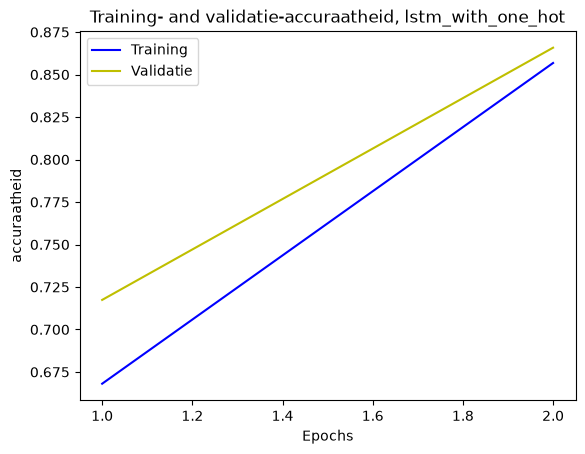

In [11]:
afbeelding("lstm_with_one_hot")

In [12]:
validatie_uitslag("lstm_with_one_hot")

Validatie-accuraatheid bij laagste loss van lstm_with_one_hot: 0.866


### One-hot-encoding niet altijd geschikt

* One-hot-encoding is feature engineering en is dus een keuze (gebruikt een aanname).
* In deze codering zal elk woord loodrecht staan op elk ander woord.
* Misschien is het logischer dat woorden die dicht bij elkaar staan in betekenis (semantisch) ook dicht bij elkaar staan in de ruimte van de codering.
* Bovendien leren deze modellen zeer langzaam, omdat de dataset erg groot is.
    * Lukt niet om uit voeren op "mijn" CPU.
    * Op COLAB met GPU ongeveer 11 minuten per epoch

### *Word embeddings*
*Word embeddings* zijn vectorrepresentaties van woorden waar de semantische afstand tussen woorden overeenkomt met de meetkundige afstand van de vectoren.

Dit maakt de vectoren lager dimensionaal en minder ijl (minder sparse) vergeleken met one-hot-encoding.

Typische voorbeelden van dimensies in een word embedding zouden de volgende begrippen kunnen zijn

- "geslacht"
- "meervoud".

Als we vanaf het woord "koning" over de dimensie "geslacht" in de richting van "vrouw" wandelen, vinden we zoiets als "koningin".

### Hoe verkrijgt men een *word embedding*?
- Zelf trainen samen met het probleem dat je oplost.<br>
Begin met willekeurige vectoren in de inbedding en leer de juiste vectoren zoals je de gewichten van het netwerk leert.
- Maak gebruik van al bestaande inbedding. Dit zijn pretrained word embeddings.
- Maak gebruik van pretrained word embedding dat je zelf hebt getraind.

### Zelf een inbedding maken

* Beeld een index (geheel getal) af op een vector van specifieke lengte (*hidden dimensions*).
* Eenvoudig in $\texttt{Keras}$ middels een [$\texttt{Embedding}$-laag](https://keras.io/api/layers/core_layers/embedding/).
* Veel teksten maken gebruik van padding (we eisen een lengte van 600 woorden).
* De informatie in het geheugen van de RNN zal verdwijnen als het aan het eind steeds de nullen ziet.
* Een manier om dit te voorkomen is middels masking.
* Als men dit aanzet, zal de RNN deze waarden overslaan.

### LSTM (bidirectional) met $\texttt{Embedding}$-laag.


In [13]:
hidden_dim = 64
inputs = keras.Input(shape=(max_length,), dtype="int32")
x = keras.layers.Embedding(
    input_dim=max_tokens,
    output_dim=hidden_dim,
    mask_zero=True,
)(inputs)
x = keras.layers.Bidirectional(keras.layers.LSTM(hidden_dim))(x)
x = keras.layers.Dropout(0.5)(x)
outputs = keras.layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="lstm_with_embedding")
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [14]:
#| output: false
'''naam = model.name
model_pad = "models/"+naam+".keras"
hist_pad = "models/"+naam+".hist"

history = model.fit(
    sequence_train_ds,
    validation_data=sequence_val_ds,
    epochs=10,
#    callbacks=[early_stopping],
)

with open(hist_pad, 'wb') as file:
    pickle.dump(history.history, file)

model.save(model_pad)
# +- 4 minuten per epoch op een CPU'''

'naam = model.name\nmodel_pad = "models/"+naam+".keras"\nhist_pad = "models/"+naam+".hist"\n\nhistory = model.fit(\n    sequence_train_ds,\n    validation_data=sequence_val_ds,\n    epochs=10,\n#    callbacks=[early_stopping],\n)\n\nwith open(hist_pad, \'wb\') as file:\n    pickle.dump(history.history, file)\n\nmodel.save(model_pad)\n# +- 4 minuten per epoch op een CPU'

In [15]:
model = keras.saving.load_model("models/lstm_with_embedding.keras")
model.summary()

Model: "lstm_with_embedding"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 600)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 600, 64)   │  1,920,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 600)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        129 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,958,533 (22.73 MB)

 Trainable params: 1,986,177 (7.58 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,972,356 (15.15 MB)

* Minder dan 2 miljoen gewichten
* Ongeveer 4 minuten per epoch op CPU

### LSTM met $\texttt{Embedding}$-laag - Resultaat


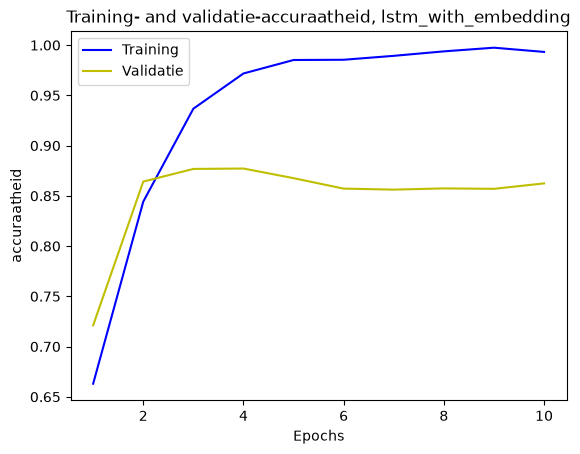

In [16]:
afbeelding("lstm_with_embedding")

In [17]:
validatie_uitslag("lstm_with_embedding")

Validatie-accuraatheid bij laagste loss van lstm_with_embedding: 0.877


Vergelijk met prestatie van bag-of-words-modellen en het vorige model.

### Is een token embedding wel of niet nuttig?

* [DLP] claimt dat zo een inbedding de prestatie "dramatisch kan verbeteren"
* Het probleem is dat de we te weinig data hebben
* Er wordt overfit voordat we een juiste inbedding kunnen leren
* Oplossing: pre-training

### Wat is pre-training

* Op een unsupervised manier proberen een "nuttige" inbedding te vinden.
* De aanname (of hoop) is dat als het voor het ene geval nuttig is, het ook nuttig is voor ons geval.

<br>

* Dit kan op vergelijkbare datasets (zelfde domein)
* Maar kan ook op willekeurige tekst (zelfde taal)

### Continuous Bag of Words (CBOW) model - idee

* We proberen een woord correct te voorspellen met als invoer de woorden eromheen.
* Het model heeft als invoer een vast aantal woorden
* Deze woorden worden ingebed en we nemen het gemiddelde van deze ingebedde woorden
* Met dit gemiddelde proberen we het middelste woord te voorspellen

<br>

* We hebben een dataset zonder labels (50 duizend recensies)
* Voeg daar de traindata (zonder labels) aan toe

In [18]:
imdb_vocabulary = text_vectorization.get_vocabulary()
tokenize_no_padding = keras.layers.TextVectorization(
    vocabulary=imdb_vocabulary,
    split="whitespace",
    output_mode="int",
)

In [19]:
#| output: false

# Words to the left or right of label
context_size = 4
# Total window size
window_size = 9

def window_data(token_ids):
    num_windows = tf.maximum(tf.size(token_ids) - context_size * 2, 0)
    windows = tf.range(window_size)[None, :]
    windows = windows + tf.range(num_windows)[:, None]
    windowed_tokens = tf.gather(token_ids, windows)
    return tf.data.Dataset.from_tensor_slices(windowed_tokens)

def split_label(window):
    left = window[:context_size]
    right = window[context_size + 1 :]
    bag = tf.concat((left, right), axis=0)
    label = window[4]
    return bag, label

# Uses all training data, including the unsup/ directory
dataset = text_dataset_from_directory(
    "C:/Users/Ik/.keras/datasets/imdb/aclImdb/train", batch_size=None
)
# Drops label
dataset = dataset.map(lambda x, y: x, num_parallel_calls=8)
# Tokenizes
dataset = dataset.map(tokenize_no_padding, num_parallel_calls=8)
# Creates context windows
dataset = dataset.interleave(window_data, cycle_length=8, num_parallel_calls=8)
# Splits middle wonder into a label
dataset = dataset.map(split_label, num_parallel_calls=8)

Found 75000 files belonging to 3 classes.


In [20]:
hidden_dim = 64
inputs = keras.Input(shape=(2 * context_size,))
cbow_embedding = layers.Embedding(
    max_tokens,
    hidden_dim,
    name="cbow_embedding",
)
x = cbow_embedding(inputs)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(max_tokens, activation="sigmoid")(x)
cbow_model = keras.Model(inputs, outputs)
cbow_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)

### Voorbeeld CBOW-model - netwerk

In [21]:
#| output: false
cbow_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbow_embedding (Embedding)      │ (None, 8, 64)          │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30000)          │     1,950,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,870,000 (14.76 MB)

 Trainable params: 3,870,000 (14.76 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
#| output: false

'''dataset = dataset.batch(1024).cache()
cbow_model.fit(dataset, epochs=4)

# duurt ongeveer 4 uur op CPU
# op COLAB met GPU ongeveer 14 minuten

cbow_model.save("cbow_model_COLAB.keras")

from google.colab import files  
files.download("cbow_model_COLAB.keras")
'''

'dataset = dataset.batch(1024).cache()\ncbow_model.fit(dataset, epochs=4)\n\n# duurt ongeveer 4 uur op CPU\n# op COLAB met GPU ongeveer 14 minuten\n\ncbow_model.save("cbow_model_COLAB.keras")\n\nfrom google.colab import files  \nfiles.download("cbow_model_COLAB.keras")\n'

In [23]:
#loaded_model = keras.saving.load_model("models/cbow_model_COLAB.keras")
cbow_model = keras.models.load_model("models/cbow_model.keras")

In [24]:
#| output: false
cbow_model.layers[1].get_weights()

[array([[-1.8854130e-02, -4.1606523e-02,  7.9240315e-03, ...,
         -4.9881823e-03, -6.9455504e-03, -4.6795119e-02],
        [-4.7900108e-01,  1.9196346e-01,  1.7440459e-01, ...,
         -7.8905672e-02, -2.3108192e-01, -2.9031071e-01],
        [ 5.3218913e-01, -1.2469764e+00,  6.4522809e-01, ...,
          9.1402113e-01, -9.2847651e-01,  7.8403878e-01],
        ...,
        [-4.1859668e-01, -7.0198648e-02,  4.3726692e-01, ...,
          1.2254215e-01, -4.6614075e-01, -2.6506072e-01],
        [ 2.7720508e-01,  1.2517183e-01,  1.8290891e-01, ...,
          3.4951378e-04,  1.1284270e-01, -6.9389296e-01],
        [-9.5546737e-02,  7.9316103e-01, -2.6404965e-01, ...,
          3.5797542e-01,  1.6359419e-01, -2.5402045e-01]],
       shape=(30000, 64), dtype=float32)]

In [25]:
cbow_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbow_embedding (Embedding)      │ (None, 8, 64)          │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 30000)          │     1,950,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,610,002 (44.29 MB)

 Trainable params: 3,870,000 (14.76 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,740,002 (29.53 MB)

* Minder dan 4 miljoen gewichten
* Ongeveer 1 uur per epoch op CPU
* Ongeveer 4 minuten per opoch op COLAB met GPU

In [26]:
inputs = keras.Input(shape=(max_length,))
lstm_embedding = layers.Embedding(
    input_dim=max_tokens,
    output_dim=hidden_dim,
    mask_zero=True,
)
x = lstm_embedding(inputs)
x = layers.Bidirectional(layers.LSTM(hidden_dim))(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="lstm_with_cbow")

In [27]:
#| output: false

#lstm_embedding.embeddings.assign(cbow_embedding.embeddings)
#lstm_embedding.embeddings.assign(loaded_model.layers[1].get_weights()[0])

cbow_embedding = cbow_model.get_layer("cbow_embedding")
lstm_embedding.embeddings.assign(cbow_embedding.embeddings)

<Variable path=cbow_embedding/embeddings, shape=(30000, 64), dtype=float32, value=[[-1.8854130e-02 -4.1606523e-02  7.9240315e-03 ... -4.9881823e-03
  -6.9455504e-03 -4.6795119e-02]
 [-4.7900108e-01  1.9196346e-01  1.7440459e-01 ... -7.8905672e-02
  -2.3108192e-01 -2.9031071e-01]
 [ 5.3218913e-01 -1.2469764e+00  6.4522809e-01 ...  9.1402113e-01
  -9.2847651e-01  7.8403878e-01]
 ...
 [-4.1859668e-01 -7.0198648e-02  4.3726692e-01 ...  1.2254215e-01
  -4.6614075e-01 -2.6506072e-01]
 [ 2.7720508e-01  1.2517183e-01  1.8290891e-01 ...  3.4951378e-04
   1.1284270e-01 -6.9389296e-01]
 [-9.5546737e-02  7.9316103e-01 -2.6404965e-01 ...  3.5797542e-01
   1.6359419e-01 -2.5402045e-01]]>

In [28]:
#| output: false

'''naam = model.name
model_pad = "models/"+naam+".keras"
hist_pad = "models/"+naam+".hist"

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    sequence_train_ds,
    validation_data=sequence_val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

# ongeveer 15 min. per epoch op CPU

with open(hist_pad, 'wb') as file:
    pickle.dump(history.history, file)

model.save(model_pad)'''


'naam = model.name\nmodel_pad = "models/"+naam+".keras"\nhist_pad = "models/"+naam+".hist"\n\nmodel.compile(\n    optimizer="adam",\n    loss="binary_crossentropy",\n    metrics=["accuracy"],\n)\n\nhistory = model.fit(\n    sequence_train_ds,\n    validation_data=sequence_val_ds,\n    epochs=10,\n    callbacks=[early_stopping],\n)\n\n# ongeveer 15 min. per epoch op CPU\n\nwith open(hist_pad, \'wb\') as file:\n    pickle.dump(history.history, file)\n\nmodel.save(model_pad)'

### LSTM (bidirectional) met CBOW-laag
Gebruik de gewichten van de cbow-inbedding-laag in onderstaand model.

In [29]:
model.summary()

Model: "lstm_with_cbow"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 600)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 600, 64)   │  1,920,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 600)       │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128)       │     66,048 │ embedding_1[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │        129 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,986,177 (7.58 MB)

 Trainable params: 1,986,177 (7.58 MB)

 Non-trainable params: 0 (0.00 B)

### Voorbeeld CBOW-model - resultaat

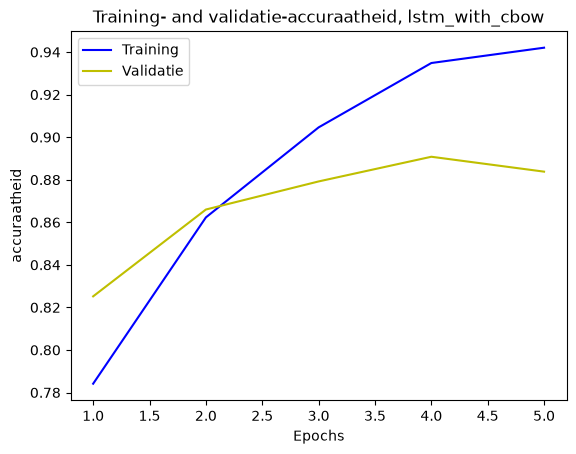

In [30]:
afbeelding("lstm_with_cbow")

In [31]:
validatie_uitslag("lstm_with_cbow")

Validatie-accuraatheid bij laagste loss van lstm_with_cbow: 0.891


### Al bestaande pretrained word embeddings

* Bijvoorbeeld $\texttt{Word2vec}$ uit 2013 en $\texttt{GloVe}$ uit 2014
* Hier komen we in een volgende les op terug
* Zie vorige editie van [DLP] voor een implementatie van zo een inbedding.

In [32]:
#| output: false

# zie http://nlp.stanford.edu/data/glove.6B.zip voor de datasets
path_to_glove_file = "/Users/Ik/backup_2308/2022-2023/AAI/MenT/Chollet/glove.6B.100d.txt"

embeddings_index = {}
with open(path_to_glove_file, encoding="utf8") as f:
    for line in f:
        word, coefs = line.split(maxsplit=1)
        coefs = np.fromstring(coefs, "f", sep=" ")
        embeddings_index[word] = coefs

embedding_dim = 100

vocabulary = text_vectorization.get_vocabulary()
word_index = dict(zip(vocabulary, range(len(vocabulary))))

embedding_matrix = np.zeros((max_tokens, embedding_dim))
for word, i in word_index.items():
    if i < max_tokens:
        embedding_vector = embeddings_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector
        
embedding_layer = layers.Embedding(
    max_tokens,
    embedding_dim,
    embeddings_initializer=keras.initializers.Constant(embedding_matrix),
    trainable=False,
    mask_zero=True,
)

inputs = keras.Input(shape=(None,), dtype="int64")
embedded = embedding_layer(inputs)
x = layers.Bidirectional(layers.GRU(32))(embedded)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])

'''callbacks = [
    keras.callbacks.ModelCheckpoint("models/glove_embeddings_sequence_model",
                                    save_best_only=True)
]'''

# 5 minuten per epoch op laptop met cpu
# 30-50 seconden per epoch op colab met gpu 

'''history = model.fit(int_train_ds,
                    epochs=15,
                    validation_data=int_val_ds,
                    callbacks=callbacks)

with open('models/glove_embeddings_sequence_model.hist', 'wb') as file:
    pickle.dump(history.history, file)'''

"history = model.fit(int_train_ds,\n                    epochs=15,\n                    validation_data=int_val_ds,\n                    callbacks=callbacks)\n\nwith open('models/glove_embeddings_sequence_model.hist', 'wb') as file:\n    pickle.dump(history.history, file)"

In [33]:
#| output: false

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 100) │  3,000,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, None)      │          0 │ input_layer_3[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 64)        │     25,728 │ embedding_2[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ bidirectional_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,025,793 (11.54 MB)

 Trainable params: 25,793 (100.75 KB)

 Non-trainable params: 3,000,000 (11.44 MB)

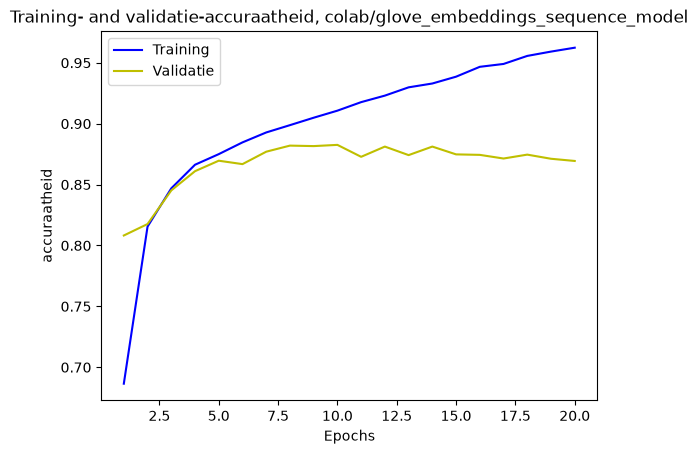

In [34]:
#| output: false

afbeelding("colab/glove_embeddings_sequence_model", colab=1)

In [35]:
#| output: false

validatie_uitslag("colab/glove_embeddings_sequence_model", colab=1)

Beste Validatie-accuraatheid van colab/glove_embeddings_sequence_model: 0.883


### bag-of-words models of sequence models
Vuistregel om model te kiezen op prestatie voor tekstclassificatie:

<br>

$$
\frac{\textrm{aantal waarnemingen}}{\textrm{gemiddelde lengte van waarnemingen}}
\begin {cases}
< 1500, \textrm { bag-of-bigrams}\\
>1500, \textrm { sequence model}
\end {cases}
$$

<br>

Zie [http://mng.bz/AOzK](http://mng.bz/AOzK)

<br>

Uit [DLP]<br>
*"If you are working in an environment where compute is limited and you can sacrifice some accuracy, set-based models can often be the most cost-effective approach''*

### Sequence-to-sequence modelling

We weten nu hoe we tekst kunnen classificeren.

Maar wat als we van tekst naar tekst willen?

- Vertalen
- Samenvatten
- Vragen beantwoorden
- Chatbot
- Aanvullen van tekst
- $\dots$

Kunnen we dat oplossen als een classificatie-probleem?


### Sequence-to-sequence als classificatie

* Van tekst naar tekst betekent van een reeks getallen naar een reeks getallen
* Een zin van vier woorden met een vocabulary van 20 duizend woorden geeft al 160 biljard ($160\, 10^{15}$) mogelijkheden.
* Als we volgorde niet belangrijk vinden zijn dit nog steeds heel veel opties en eigenlijk niet te doen.

<br>

Oplossing: een taalmodel.


### Taalmodel


Een model dat de kans op een symbool (gegeven de voorgaande symbolen) geeft, noemen we een taalmodel (*language model*)

<br>

Een *language model* leert
$$
P(\textrm{token} | \textrm {vorige tokens})
$$
en kan door dit steeds opnieuw toe te passen een groot stuk tekst produceren.

### "Shakespeare language model" (Hfst 15)

* Data: sonnetten en toneelstukken van Shakespeare.
* Voorbeeld:

In [36]:
filename = keras.utils.get_file(
    fname="C:/Users/Ik/.keras/datasets/shakespeare.txt",
    origin=(
        "https://storage.googleapis.com/download.tensorflow.org/"
        "data/shakespeare.txt"
    ),
)
shakespeare = open(filename, "r").read()

In [37]:
print(shakespeare[:250])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



### "Shakespeare language model", vervolg

* We voorspellen op karakterniveau
* We gaan uit van teksten van 100 karakters
* Geen standaardisatie (leestekens en hoofdletters)
* Grootte van vocabulary:

In [38]:
# The chunk size we will use during training. We only train on
# sequences of 100 characters at a time.
sequence_length = 100

def split_input(input, sequence_length):
    for i in range(0, len(input), sequence_length):
        yield input[i : i + sequence_length]

features = list(split_input(shakespeare[:-1], sequence_length))
labels = list(split_input(shakespeare[1:], sequence_length))
dataset = tf.data.Dataset.from_tensor_slices((features, labels))

In [39]:
tokenizer = layers.TextVectorization(
    standardize=None,
    split="character",
    output_sequence_length=sequence_length,
)
tokenizer.adapt(dataset.map(lambda text, labels: text))

In [40]:
vocabulary_size = tokenizer.vocabulary_size()
vocabulary_size

67

<br>

* We willen een karakter voorspellen met de voorgaande karakters
* Als voorspellende variabelen kiezen we de eerste 99 karakters
* Als voorspelde variabelen kiezen we de laatste 99 karakters.

In [41]:
x, y = next(dataset.as_numpy_iterator())
x[:50].decode('UTF-8'), y[:50].decode('UTF-8')

('First Citizen:\nBefore we proceed any further, hear',
 'irst Citizen:\nBefore we proceed any further, hear ')

### "Shakespeare language model", model

In [42]:
dataset = dataset.map(
    lambda features, labels: (tokenizer(features), tokenizer(labels)),
    num_parallel_calls=8,
)
training_data = dataset.shuffle(10_000).batch(64).cache()

In [43]:
embedding_dim = 256
hidden_dim = 1024

inputs = layers.Input(shape=(sequence_length,), dtype="int", name="token_ids")
x = layers.Embedding(vocabulary_size, embedding_dim)(inputs)
x = layers.GRU(hidden_dim, return_sequences=True)(x)
x = layers.Dropout(0.1)(x)
# Outputs a probability distribution over all potential tokens in our
# vocabulary
outputs = layers.Dense(vocabulary_size, activation="softmax")(x)
model = keras.Model(inputs, outputs)

In [44]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_3 (Embedding)         │ (None, 100, 256)       │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 100, 1024)      │     3,938,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 100, 1024)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100, 67)        │        68,675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,024,131 (15.35 MB)

 Trainable params: 4,024,131 (15.35 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#| output: false

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)
model.fit(training_data, epochs=20) # was 20

model.save("models/taal_model.keras")

175/175 ━━━━━━━━━━━━━━━━━━━━ 296s 2s/step - loss: 1.8134 - sparse_categorical_accuracy: 0.4641


In [42]:
#taal_model = keras.saving.load_model("models/taal_model.keras")
taal_model = keras.saving.load_model("models/taal_model_COLAB.keras")

# Creates a model that receives and outputs the RNN state
inputs = keras.Input(shape=(1,), dtype="int", name="token_ids")
input_state = keras.Input(shape=(hidden_dim,), name="state")

x = layers.Embedding(vocabulary_size, embedding_dim)(inputs)
x, output_state = layers.GRU(hidden_dim, return_state=True)(
    x, initial_state=input_state
)
outputs = layers.Dense(vocabulary_size, activation="softmax")(x)
generation_model = keras.Model(
    inputs=(inputs, input_state),
    outputs=(outputs, output_state),
)
# Copies the parameters from the original model
generation_model.set_weights(taal_model.get_weights())



### Hoe genereert men tekst?

Stappenplan

- Train een language model om een symbool te voorspellen, gegeven de voorgaande symbolen.
- Kies een symbool (*conditioning data*) als startreeks voor het model. Kies een nieuw symbool (gebruik $P(\textrm{token} | \textrm {vorige tokens})$) en voeg dat toe aan de reeks.
- Gebuik de nieuwe reeks als invoer voor het model en voeg een nieuw symbool toe. Herhaal tot stopcriterium.

### "Shakespeare language model", genereren

* Om het netwerk in een $\texttt{for}$-loop tekst te laten genereren moeten we enkele aanpassingen maken.
* Invoer is de vorige token en bijbehorende toestand (van het RNN)
* Uitvoer is een nieuwe token en de bijbehorende nieuwe toestand

<br>

* Maak gebruik van een "prompt"
* Voer de tokens van de prompt 1 voor 1 in
* De laatste toestand bevat de informatie van de prompt
* De $\texttt{for}$-loop kan starten tot een stop-criterium

### "Shakespeare language model", resultaat

In [43]:
tokens = tokenizer.get_vocabulary()
token_ids = range(vocabulary_size)
char_to_id = dict(zip(tokens, token_ids))
id_to_char = dict(zip(token_ids, tokens))

prompt = """
KING RICHARD III:
"""

In [44]:
input_ids = [char_to_id[c] for c in prompt]
state = keras.ops.zeros(shape=(1, hidden_dim))
for token_id in input_ids:
    inputs = keras.ops.expand_dims([token_id], axis=0)
    # Feeds the prompt character by character to update state
    predictions, state = generation_model.predict((inputs, state), verbose=0)

In [45]:
generated_ids = []
max_length = 250
# Generates characters one by one, computing a new state each iteration
for i in range(max_length):
    # The next character is the output index with the highest
    # probability.
    next_char = int(np.argmax(predictions, axis=-1)[0])
    generated_ids.append(next_char)
    inputs = keras.ops.expand_dims([next_char], axis=0)
    predictions, state = generation_model.predict((inputs, state), verbose=0)

In [46]:
output = "".join([id_to_char[token_id] for token_id in generated_ids])
print(prompt + output)


KING RICHARD III:
And I think you a subject a common money.

PAULINA:
And I come to the Tower.

CLARENCE:
What says he that? but the duke?

Second Murderer:
And I think you a subject.

ANGELO:
What say you?

Second Citizen:
What should you love, I think it were a fear
